# StateBridge × TwinAPI — Reproduction
Run All from an empty directory. Finds local files or a Kaggle Dataset, otherwise shallow-clones [the public repository](https://github.com/GGGODLIN/gemma4-state-bridge). Internet is needed for the first clone/dependency installation. Offline without data: precomputed summary only, clearly marked; no live-verification claim. Arm 3 is a fixed HTTP distractor; its legacy identifier is retained. Replay writes to a working-directory temporary folder; mounted inputs remain read-only.

In [1]:
"""Notebook 自足啟動；本檔原碼會嵌入 Notebook，不依賴本機匯入路徑。"""

import importlib.metadata
import json
import os
from pathlib import Path
import subprocess
import sys
import tempfile

PUBLIC_REPO = "https://github.com/GGGODLIN/gemma4-state-bridge.git"


def is_statebridge_repo(path):
  return all((path / item).is_file() for item in (
    "artifacts/raw_llm_generations.jsonl",
    "artifacts/metrics_ssot.json",
    "artifacts/twinapi_audit.json",
    "scripts/build_ssot.py",
    "skills/state-bridge/scripts/statebridge_core.py",
  ))


def locate_statebridge_repo():
  cwd = Path.cwd()
  for parent in (cwd, *cwd.parents):
    for candidate in (parent, parent / "gemma4-state-bridge"):
      if is_statebridge_repo(candidate):
        print("Source: local repository")
        return candidate
  input_root = Path(os.environ.get("STATEBRIDGE_INPUT_ROOT", "/kaggle/input"))
  if input_root.exists():
    for raw in sorted(input_root.rglob("raw_llm_generations.jsonl")):
      candidate = raw.parent.parent
      if is_statebridge_repo(candidate):
        print("Source: mounted Kaggle Dataset")
        return candidate
  if os.environ.get("STATEBRIDGE_OFFLINE") != "1":
    destination = Path(tempfile.mkdtemp(prefix="statebridge-source-", dir=cwd))
    repo_url = os.environ.get("STATEBRIDGE_REPO_URL", PUBLIC_REPO)
    try:
      subprocess.run(
        ["git", "clone", "--depth", "1", repo_url, str(destination)],
        check=True, capture_output=True, text=True, timeout=90,
      )
      if is_statebridge_repo(destination):
        print("Source: shallow Git clone")
        return destination
    except (OSError, subprocess.SubprocessError) as exc:
      print(f"Clone unavailable ({type(exc).__name__}).")
  print("SUMMARY ONLY: precomputed results; statistics and figures have NOT been recomputed.")
  print("Enable Kaggle Internet, or mount a Dataset containing the repository under /kaggle/input/<dataset>/.")
  return None


def require_replay_dependencies():
  required = {"requests": "2.34.2", "httpx": "0.28.1"}
  missing = []
  for package, version in required.items():
    try:
      installed = importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
      installed = None
    if installed != version:
      missing.append(f"{package}=={version}")
  try:
    import matplotlib
  except ImportError:
    missing.append("matplotlib")
  if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
  print("Replay dependencies: requests==2.34.2, httpx==0.28.1, matplotlib")

ROOT = locate_statebridge_repo()
ssot = {'project': 'StateBridge x TwinAPI', 'benchmark': {'name': 'StateBridge-Bench', 'total_workflows': 30, 'families_count': 5, 'workflows_per_family': 6, 'total_llm_generations': 240, 'total_evaluated_runs': 270, 'replay_elapsed_sec': 31.801}, 'twinapi_audit': {'requests_top_level_functions': ['delete', 'get', 'head', 'options', 'patch', 'post', 'put', 'request', 'session'], 'top_level_exact_name_overlap': ['delete', 'get', 'head', 'options', 'patch', 'post', 'put', 'request'], 'top_level_exact_name_overlap_ratio': 0.8889, 'session_client_core_overlap': ['close', 'delete', 'get', 'head', 'options', 'patch', 'post', 'put', 'request', 'send'], 'session_client_core_overlap_ratio': 0.8333, 'stateful_false_friend_count': 12, 'total_pairs_audited': 15, 'mean_false_friend_embedding_cosine_256d': 0.873, 'mean_false_friend_short_name_similarity': 0.7876}, 'models': {'gemma-4-31b-it': {'full_model_id': 'google/models/gemma-4-31b-it', 'arms': {'arm1_codemod': {'pass_count': 0, 'total': 30, 'solve_rate': 0.0, 'outcome_counts': {'PRE_HTTP_RUNTIME_ERROR': 13, 'STEP_K_WIRE_DIVERGENCE': 17}, 'mean_prompt_tokens': 0, 'mean_completion_tokens': 0, 'mean_reasoning_tokens': 0, 'mean_visible_completion_tokens': 0, 'mean_thought_chars': 0, 'mean_visible_chars': 510.1, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 0, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 0, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 0, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 0, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 0, 'total': 6}}}, 'arm2_target_only': {'pass_count': 4, 'total': 30, 'solve_rate': 0.1333, 'outcome_counts': {'PASS_EQUIVALENT': 4, 'STEP_K_WIRE_DIVERGENCE': 26}, 'mean_prompt_tokens': 497.7, 'mean_completion_tokens': 193.5, 'mean_reasoning_tokens': 1143.0, 'mean_visible_completion_tokens': 193.5, 'mean_thought_chars': 4572.2, 'mean_visible_chars': 628.7, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 1, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 1, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 0, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 1, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 1, 'total': 6}}}, 'arm3_embedding_topk': {'pass_count': 4, 'total': 30, 'solve_rate': 0.1333, 'outcome_counts': {'PASS_EQUIVALENT': 4, 'STEP_K_WIRE_DIVERGENCE': 26}, 'mean_prompt_tokens': 637.7, 'mean_completion_tokens': 188.9, 'mean_reasoning_tokens': 1191.2, 'mean_visible_completion_tokens': 188.9, 'mean_thought_chars': 4764.6, 'mean_visible_chars': 608.3, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 1, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 1, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 0, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 1, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 1, 'total': 6}}}, 'arm4_callgraph_slice': {'pass_count': 27, 'total': 30, 'solve_rate': 0.9, 'outcome_counts': {'PASS_EQUIVALENT': 27, 'STEP_K_WIRE_DIVERGENCE': 3}, 'mean_prompt_tokens': 799.9, 'mean_completion_tokens': 234.7, 'mean_reasoning_tokens': 2099.0, 'mean_visible_completion_tokens': 234.7, 'mean_thought_chars': 8396.0, 'mean_visible_chars': 769.1, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 6, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 6, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 5, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 6, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 4, 'total': 6}}}, 'arm5_unrelated_slice': {'pass_count': 5, 'total': 30, 'solve_rate': 0.1667, 'outcome_counts': {'PASS_EQUIVALENT': 5, 'STEP_K_WIRE_DIVERGENCE': 25}, 'mean_prompt_tokens': 702.7, 'mean_completion_tokens': 196.0, 'mean_reasoning_tokens': 1411.8, 'mean_visible_completion_tokens': 196.0, 'mean_thought_chars': 5647.3, 'mean_visible_chars': 637.6, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 1, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 1, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 1, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 1, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 1, 'total': 6}}}}, 'paired_comparisons': {'arm4_vs_arm1': {'n': 30, 'pass_a': 27, 'pass_b': 0, 'rate_a': 0.9, 'rate_b': 0.0, 'diff': 0.9, 'discordant_a_wins': 27, 'discordant_b_wins': 0, 'both_pass': 0, 'both_fail': 3, 'mcnemar_p': 1.4901161193847656e-08, 'ci95_low': 0.7667, 'ci95_high': 1.0}, 'arm4_vs_arm2': {'n': 30, 'pass_a': 27, 'pass_b': 4, 'rate_a': 0.9, 'rate_b': 0.1333, 'diff': 0.7667, 'discordant_a_wins': 23, 'discordant_b_wins': 0, 'both_pass': 4, 'both_fail': 3, 'mcnemar_p': 2.384185791015625e-07, 'ci95_low': 0.6, 'ci95_high': 0.9}, 'arm4_vs_arm3': {'n': 30, 'pass_a': 27, 'pass_b': 4, 'rate_a': 0.9, 'rate_b': 0.1333, 'diff': 0.7667, 'discordant_a_wins': 23, 'discordant_b_wins': 0, 'both_pass': 4, 'both_fail': 3, 'mcnemar_p': 2.384185791015625e-07, 'ci95_low': 0.6, 'ci95_high': 0.9}, 'arm4_vs_arm5': {'n': 30, 'pass_a': 27, 'pass_b': 5, 'rate_a': 0.9, 'rate_b': 0.1667, 'diff': 0.7333, 'discordant_a_wins': 23, 'discordant_b_wins': 1, 'both_pass': 4, 'both_fail': 2, 'mcnemar_p': 2.9802322387695312e-06, 'ci95_low': 0.5333, 'ci95_high': 0.9}}}, 'gemma-4-26b-a4b-it': {'full_model_id': 'google/models/gemma-4-26b-a4b-it', 'arms': {'arm1_codemod': {'pass_count': 0, 'total': 30, 'solve_rate': 0.0, 'outcome_counts': {'PRE_HTTP_RUNTIME_ERROR': 13, 'STEP_K_WIRE_DIVERGENCE': 17}, 'mean_prompt_tokens': 0, 'mean_completion_tokens': 0, 'mean_reasoning_tokens': 0, 'mean_visible_completion_tokens': 0, 'mean_thought_chars': 0, 'mean_visible_chars': 510.1, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 0, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 0, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 0, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 0, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 0, 'total': 6}}}, 'arm2_target_only': {'pass_count': 4, 'total': 30, 'solve_rate': 0.1333, 'outcome_counts': {'PASS_EQUIVALENT': 4, 'STEP_K_WIRE_DIVERGENCE': 26}, 'mean_prompt_tokens': 497.7, 'mean_completion_tokens': 203.1, 'mean_reasoning_tokens': 2130.3, 'mean_visible_completion_tokens': 203.1, 'mean_thought_chars': 8521.7, 'mean_visible_chars': 663.0, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 1, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 1, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 0, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 1, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 1, 'total': 6}}}, 'arm3_embedding_topk': {'pass_count': 4, 'total': 30, 'solve_rate': 0.1333, 'outcome_counts': {'PASS_EQUIVALENT': 4, 'STEP_K_WIRE_DIVERGENCE': 26}, 'mean_prompt_tokens': 637.7, 'mean_completion_tokens': 209.3, 'mean_reasoning_tokens': 2501.4, 'mean_visible_completion_tokens': 209.3, 'mean_thought_chars': 10005.8, 'mean_visible_chars': 689.3, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 1, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 1, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 0, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 1, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 1, 'total': 6}}}, 'arm4_callgraph_slice': {'pass_count': 29, 'total': 30, 'solve_rate': 0.9667, 'outcome_counts': {'PASS_EQUIVALENT': 29, 'STEP_K_WIRE_DIVERGENCE': 1}, 'mean_prompt_tokens': 799.9, 'mean_completion_tokens': 258.8, 'mean_reasoning_tokens': 3705.2, 'mean_visible_completion_tokens': 258.8, 'mean_thought_chars': 14820.8, 'mean_visible_chars': 866.7, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 6, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 6, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 5, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 6, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 6, 'total': 6}}}, 'arm5_unrelated_slice': {'pass_count': 4, 'total': 30, 'solve_rate': 0.1333, 'outcome_counts': {'PASS_EQUIVALENT': 4, 'STEP_K_WIRE_DIVERGENCE': 26}, 'mean_prompt_tokens': 702.7, 'mean_completion_tokens': 203.8, 'mean_reasoning_tokens': 2618.5, 'mean_visible_completion_tokens': 203.8, 'mean_thought_chars': 10473.7, 'mean_visible_chars': 664.9, 'by_family': {'F1_REDIRECT_FOLLOW_DEFAULT': {'pass_count': 1, 'total': 6}, 'F2_CROSS_ORIGIN_AUTH_STRIP': {'pass_count': 1, 'total': 6}, 'F3_COOKIE_JAR_SCOPING': {'pass_count': 0, 'total': 6}, 'F4_STREAM_CONTEXT_LIFECYCLE': {'pass_count': 1, 'total': 6}, 'F5_CLIENT_INIT_AND_STATUS_ERROR': {'pass_count': 1, 'total': 6}}}}, 'paired_comparisons': {'arm4_vs_arm1': {'n': 30, 'pass_a': 29, 'pass_b': 0, 'rate_a': 0.9667, 'rate_b': 0.0, 'diff': 0.9667, 'discordant_a_wins': 29, 'discordant_b_wins': 0, 'both_pass': 0, 'both_fail': 1, 'mcnemar_p': 3.725290298461914e-09, 'ci95_low': 0.9, 'ci95_high': 1.0}, 'arm4_vs_arm2': {'n': 30, 'pass_a': 29, 'pass_b': 4, 'rate_a': 0.9667, 'rate_b': 0.1333, 'diff': 0.8333, 'discordant_a_wins': 25, 'discordant_b_wins': 0, 'both_pass': 4, 'both_fail': 1, 'mcnemar_p': 5.960464477539063e-08, 'ci95_low': 0.7, 'ci95_high': 0.9667}, 'arm4_vs_arm3': {'n': 30, 'pass_a': 29, 'pass_b': 4, 'rate_a': 0.9667, 'rate_b': 0.1333, 'diff': 0.8333, 'discordant_a_wins': 25, 'discordant_b_wins': 0, 'both_pass': 4, 'both_fail': 1, 'mcnemar_p': 5.960464477539063e-08, 'ci95_low': 0.7, 'ci95_high': 0.9667}, 'arm4_vs_arm5': {'n': 30, 'pass_a': 29, 'pass_b': 4, 'rate_a': 0.9667, 'rate_b': 0.1333, 'diff': 0.8333, 'discordant_a_wins': 25, 'discordant_b_wins': 0, 'both_pass': 4, 'both_fail': 1, 'mcnemar_p': 5.960464477539063e-08, 'ci95_low': 0.7, 'ci95_high': 0.9667}}}}}
twin = ssot["twinapi_audit"]
print(f"Top-level name overlap: {twin['top_level_exact_name_overlap_ratio']*100:.1f}% (8/9)")
print(f"Session/Client overlap: {twin['session_client_core_overlap_ratio']*100:.1f}% (10/12)")
print(f"Mean 256-d audit cosine: {twin['mean_false_friend_embedding_cosine_256d']:.3f}")


Source: mounted Kaggle Dataset
Top-level name overlap: 88.9% (8/9)
Session/Client overlap: 83.3% (10/12)
Mean 256-d audit cosine: 0.873


In [2]:
if ROOT is not None:
  require_replay_dependencies()
  import shutil
  import time
  sys.path.insert(0, str(ROOT / "scripts"))
  import build_ssot as bs
  frozen_models = ssot["models"]
  replay_dir = Path(tempfile.mkdtemp(prefix="statebridge-replay-", dir=Path.cwd()))
  shutil.copy2(ROOT / "artifacts/twinapi_audit.json", replay_dir / "twinapi_audit.json")
  t0 = time.monotonic()
  ssot = bs.build_ssot(ROOT / "artifacts/raw_llm_generations.jsonl", replay_dir)
  assert ssot["models"] == frozen_models, "Live replay differs from embedded published results"
  live_elapsed = round(time.monotonic() - t0, 3)
  runs = [json.loads(line) for line in (replay_dir / "runs.jsonl").read_text().splitlines()]
  assert len(runs) == 270
  print(f"LIVE REPLAY VERIFIED: {len(runs)} runs, exact statistics match; elapsed={live_elapsed}s")
else:
  print("SUMMARY ONLY: live replay skipped; no reproduction claim.")


Replay dependencies: requests==2.34.2, httpx==0.28.1, matplotlib


LIVE REPLAY VERIFIED: 270 runs, exact statistics match; elapsed=30.264s


In [3]:
for model_key, model in ssot["models"].items():
  print(f"\n=== {model_key} ===")
  for arm_id, arm in model["arms"].items():
    print(f"{arm_id}: {arm['solve_rate']*100:.1f}% ({arm['pass_count']}/{arm['total']})")
  for comparison, stats in model["paired_comparisons"].items():
    print(f"{comparison}: p={stats['mcnemar_p']}, discordant={stats['discordant_a_wins']}:{stats['discordant_b_wins']}, CI=[{stats['ci95_low']*100:.1f}%, {stats['ci95_high']*100:.1f}%]")



=== gemma-4-31b-it ===
arm1_codemod: 0.0% (0/30)
arm2_target_only: 13.3% (4/30)
arm3_embedding_topk: 13.3% (4/30)
arm4_callgraph_slice: 90.0% (27/30)
arm5_unrelated_slice: 16.7% (5/30)
arm4_vs_arm1: p=1.4901161193847656e-08, discordant=27:0, CI=[76.7%, 100.0%]
arm4_vs_arm2: p=2.384185791015625e-07, discordant=23:0, CI=[60.0%, 90.0%]
arm4_vs_arm3: p=2.384185791015625e-07, discordant=23:0, CI=[60.0%, 90.0%]
arm4_vs_arm5: p=2.9802322387695312e-06, discordant=23:1, CI=[53.3%, 90.0%]

=== gemma-4-26b-a4b-it ===
arm1_codemod: 0.0% (0/30)
arm2_target_only: 13.3% (4/30)
arm3_embedding_topk: 13.3% (4/30)
arm4_callgraph_slice: 96.7% (29/30)
arm5_unrelated_slice: 13.3% (4/30)
arm4_vs_arm1: p=3.725290298461914e-09, discordant=29:0, CI=[90.0%, 100.0%]
arm4_vs_arm2: p=5.960464477539063e-08, discordant=25:0, CI=[70.0%, 96.7%]
arm4_vs_arm3: p=5.960464477539063e-08, discordant=25:0, CI=[70.0%, 96.7%]
arm4_vs_arm5: p=5.960464477539063e-08, discordant=25:0, CI=[70.0%, 96.7%]


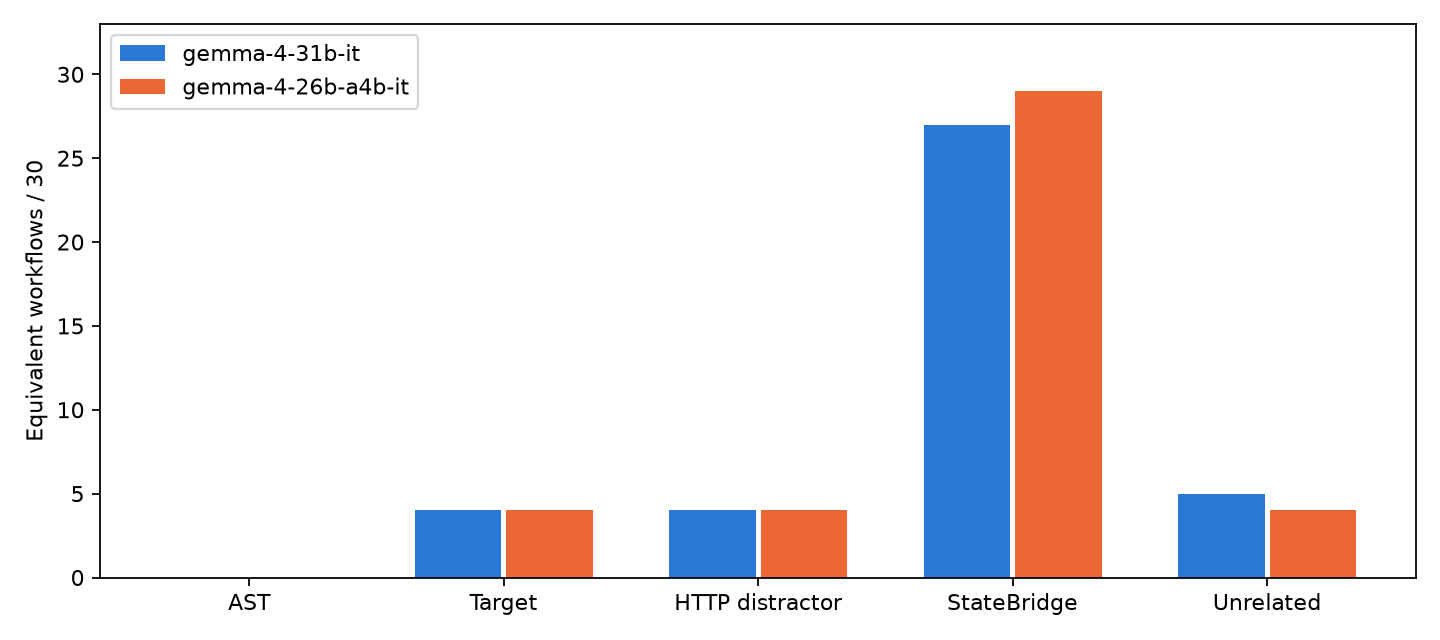

Figure generated from live replay statistics.


In [4]:
if ROOT is not None:
  import matplotlib
  matplotlib.use("Agg")
  import matplotlib.pyplot as plt
  from IPython.display import Image, display
  order = list(ssot["models"]["gemma-4-31b-it"]["arms"])
  fig, ax = plt.subplots(figsize=(9, 4))
  for i, (model_key, model) in enumerate(ssot["models"].items()):
    ax.bar([j + i * 0.36 for j in range(len(order))],
           [model["arms"][arm]["pass_count"] for arm in order],
           width=0.34, label=model_key, color=("#2a78d6", "#eb6834")[i])
  ax.set_xticks([j + 0.18 for j in range(len(order))], ["AST", "Target", "HTTP distractor", "StateBridge", "Unrelated"])
  ax.set_ylabel("Equivalent workflows / 30")
  ax.set_ylim(0, 33)
  ax.legend()
  fig.tight_layout()
  figure_path = replay_dir / "live_solve_rates.png"
  fig.savefig(figure_path, dpi=160)
  plt.close(fig)
  display(Image(filename=str(figure_path)))
  print("Figure generated from live replay statistics.")
else:
  print("SUMMARY ONLY: figures were not recomputed.")
